# Figure S1

Illustration of gene-pair testability under Fisher's exact test and DISCOVER.

- **A** (cell "Panel A"): null distribution of the overlap of *glmS* and *rho* in 42C_Tenaillon under each method. The ringed points are the most extreme overlaps each null allows. Nothing is more extreme than them, so each ringed point's height *is* that direction's p_min, compared directly with the 0.05 line.
- **B** (cell "Panel B"): the observed pattern, one column per endpoint of 42C_Tenaillon.

**Inputs:** `cache/Figure_S1_nulls.npz` and `data/analysis/ecoli/all_experiments/pairwise_all_methods_gene.csv`, against which the notebook checks the cache.

**Outputs:** `figures/Figure_S1/Figure_S1_A` and `figures/Figure_S1/Figure_S1_B`, each as .pdf, .svg and .png. Both are drawn at final print size (A 170 mm wide, B 130 mm wide), with the fonts embedded in the PDF, the SVG text in Arial and the PNG at 600 dpi.

**Environment:** `code/Figure_S1_nulls.py` (see its docstring) writes the cache in the pipeline's environment, which contains DISCOVER, and refuses to write it unless every p_min matches the pair table. This notebook runs in environment B.

Panel letters and the final layout are added in Adobe Illustrator.

In [1]:
# %% Imports and shared style
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

mpl.rcParams["svg.fonttype"] = "none"      # SVG text stays editable and is rewritten to Arial below
mpl.rcParams["pdf.fonttype"] = 42          # PDF fonts are embedded as TrueType
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["axes.linewidth"] = 0.6       # every line wider than 0.25 pt at final size
for _k in ("xtick.major.width", "ytick.major.width"):
    mpl.rcParams[_k] = 0.6
for _k in ("xtick.major.size", "ytick.major.size"):
    mpl.rcParams[_k] = 2.5

# Method colors are Figure 2B's. They separate for color-blind readers but merge in
# grayscale. Both methods are
# drawn as SOLID circles, so method is carried by color alone: the panel
# separates in color and for color-blind readers, but not in black-and-white print.
INK, MUTE = "#000000", "#6B6B6B"
FISH, DISC = "#2F6DB3", "#D1495B"
ONC_FILL, ONC_EMPTY = "#458B57", "#eef1f4"     # the oncoplot cells of Figures 4-5

# Drawn at final print size, so these are the printed point sizes.
FS_TITLE, FS_TICK, FS_NOTE, FS_PANEL = 8, 7, 7, 10
MM = 1 / 25.4
FIG_W_MM, FIG_H_MM = 170, 100                   # full-page width, in mm

# Folders. The notebook runs from code/, so the folder above it holds data/, cache/ and figures/.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"            # pipeline outputs (the results/ folder of ale-cooccurrence-nf)
FIG_DIR = ROOT / "figures/Figure_S1"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"data folder not found: {DATA_DIR}")
if not (ROOT / "code/Figure_S1.ipynb").is_file():
    raise FileNotFoundError(f"run this notebook from the code/ folder (working folder: {Path.cwd()})")
FIG_DIR.mkdir(parents=True, exist_ok=True)

CACHE = ROOT / "cache/Figure_S1_nulls.npz"
ANA_DIR = DATA_DIR / "analysis/ecoli/all_experiments"
SAVE, DPI = True, 600


In [2]:
# %% Load the cached nulls and re-check them against the pipeline
C = np.load(CACHE)
N, cA, cB, obs = int(C["N"]), int(C["count_a"]), int(C["count_b"]), int(C["observed"])
GA, GB = str(C["gene_a"]), str(C["gene_b"])
pf, pdi = C["pmf_fisher"], C["pmf_discover"]
F_XMAX, D_XMAX = int(C["fisher_xmax"]), int(C["discover_xmax"])
F_ME, F_CO = float(C["fisher_pmin_me"]), float(C["fisher_pmin_co"])
D_ME = float(np.exp(C["discover_log_pmin_me"]))
D_CO_LOG10 = float(C["discover_log_pmin_co"]) / np.log(10)

_P = pd.read_csv(ANA_DIR / "pairwise_all_methods_gene.csv", low_memory=False)
_r = _P[_P.exp.astype(str).str.startswith("42C_Tenaillon")
        & (((_P.unit1 == GA) & (_P.unit2 == GB)) | ((_P.unit1 == GB) & (_P.unit2 == GA)))].iloc[0]
for _col, _v in {"fisher_floor_mutex": F_ME, "fisher_floor_co": F_CO,
                 "discover_floor_mutex": D_ME,
                 "discover_floor_co": 10 ** D_CO_LOG10}.items():
    assert np.isclose(_v, float(_r[_col]), rtol=1e-6, atol=0), f"{_col} differs from the pipeline"
assert not (_r.fisher_testable_mutex or _r.fisher_testable_co or _r.discover_testable_mutex)
assert bool(_r.discover_testable_co)

print(f"{GB}-{GA}: N = {N}, {GA} {cA}, {GB} {cB}, observed overlap {obs}")
print(f"  Fisher    p_min  ME {F_ME:.3g}   CO {F_CO:.3g}   (most extreme overlaps 0 and {F_XMAX})")
print(f"  DISCOVER  p_min  ME {D_ME:.3g}   CO {10 ** (D_CO_LOG10 - np.floor(D_CO_LOG10)):.1f}e{int(np.floor(D_CO_LOG10))}   (most extreme overlaps 0 and {D_XMAX})")
print("  matches the pipeline: testable only for co-occurrence under DISCOVER")


glmS-rho: N = 111, rho 43, glmS 3, observed overlap 0
  Fisher    p_min  ME 0.226   CO 0.0556   (most extreme overlaps 0 and 3)
  DISCOVER  p_min  ME 0.291   CO 1.7e-223   (most extreme overlaps 0 and 111)
  matches the pipeline: testable only for co-occurrence under DISCOVER


wrote Figure_S1_B.{pdf,png,svg}


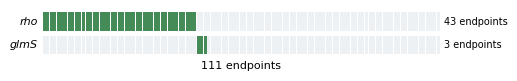

In [3]:
# %% Panel B (figA): the observed data
# Narrower than panel A, and the side margins are set in MILLIMETERS rather than as
# fractions: the row labels and row totals are fixed-width text, so fraction margins would
# clip them as the figure narrows. The margins fit those labels at these font sizes.
W_A_MM, H_A_MM = 130, 23
_L_MM, _R_MM = 10.0, 19.0
_BOT_MM, _STRIP_MM = 7.0, 12.0          # strip rows are 6 mm each
figA = plt.figure(figsize=(W_A_MM * MM, H_A_MM * MM))
axA = figA.add_axes([_L_MM / W_A_MM, _BOT_MM / H_A_MM,
                     (W_A_MM - _L_MM - _R_MM) / W_A_MM, _STRIP_MM / H_A_MM])

# Endpoints ordered rho only | glmS only | neither. No column holds both.
for r, row in enumerate([C["row_a"], C["row_b"]]):
    for j, v in enumerate(row):
        axA.add_patch(Rectangle((j + 0.06, 1 - r + 0.1), 0.88, 0.8, linewidth=0,
                                facecolor=ONC_FILL if v else ONC_EMPTY))
for y, g, c in [(1, GA, cA), (0, GB, cB)]:
    axA.text(-1.2, y + 0.5, g, ha="right", va="center", fontsize=FS_TITLE, style="italic")
    axA.text(N + 1.2, y + 0.5, f"{c} endpoints", ha="left", va="center", fontsize=FS_NOTE)
axA.set_xlim(0, N); axA.set_ylim(0, 2)
axA.set_xticks([]); axA.set_yticks([])
for s in axA.spines.values():
    s.set_visible(False)
axA.set_xlabel(f"{N} endpoints", fontsize=FS_TITLE, labelpad=3)

if SAVE:
    stem = FIG_DIR / "Figure_S1_B"
    for ext in (".pdf", ".svg"):
        figA.savefig(stem.with_suffix(ext), facecolor="white")
    figA.savefig(stem.with_suffix(".png"), dpi=DPI, facecolor="white")
    print("wrote", stem.name + ".{pdf,png,svg}")
plt.show()


wrote Figure_S1_A.{pdf,png,svg}


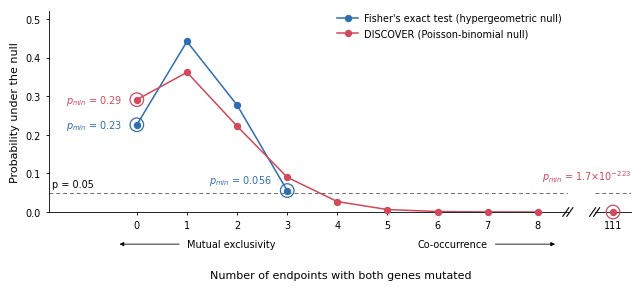

In [4]:
# %% Panel A (figB): the two null models
# The main axes are 131.75 x 51 mm, with the left edge at 14.45 mm.
H_B_MM = 78
figB = plt.figure(figsize=(FIG_W_MM * MM, H_B_MM * MM))
ax  = figB.add_axes([0.085, 21.5 / H_B_MM, 0.775, 51.0 / H_B_MM])
axR = figB.add_axes([0.900, 21.5 / H_B_MM, 0.055, 51.0 / H_B_MM], sharey=ax)

K = 8                                          # DISCOVER's mass beyond 8 is < 1e-4
kf, kd = np.arange(len(pf)), np.arange(K + 1)
ax.plot(kf, pf, "-", color=FISH, lw=1.1, zorder=3)
ax.plot(kf, pf, "o", ms=4.2, mfc=FISH, mec=FISH, mew=1.1, zorder=4)
ax.plot(kd, pdi[:K + 1], "-", color=DISC, lw=1.1, zorder=3)
# unclipped: the tail points sit on the axis line, and would otherwise be drawn as half circles
ax.plot(kd, pdi[:K + 1], "o", ms=4.2, mfc=DISC, mec=DISC, mew=1.1, zorder=4, clip_on=False)
# p_min here is zero at this scale, so the marker sits ON the axis line:
# draw it unclipped and above the spine so the full circle stays visible.
axR.plot([D_XMAX], [pdi[D_XMAX]], "o", ms=4.2, mfc=DISC, mec=DISC, mew=1.1,
         zorder=6, clip_on=False)

# The most extreme possible overlap in each direction, ringed and labeled with its p_min.
# Nothing is more extreme, so its probability alone IS the smallest p-value the pair can
# produce in that direction.
RING = dict(s=95, facecolor="none", lw=0.9, zorder=5)
ax.scatter([0], [pf[0]], edgecolor=FISH, **RING)
ax.scatter([0], [pdi[0]], edgecolor=DISC, **RING)
ax.scatter([F_XMAX], [pf[F_XMAX]], edgecolor=FISH, **RING)
axR.scatter([D_XMAX], [pdi[D_XMAX]], edgecolor=DISC, clip_on=False, **RING)

# One threshold line across the whole panel, continued past the axis break. Note that a
# p-value is a TAIL area: the height of the curve equals a p-value only at the ringed
# extremes, which is why those points carry a p_min label.
ax.axhline(0.05, color=MUTE, ls=(0, (4, 3)), lw=0.7, zorder=1)
axR.axhline(0.05, color=MUTE, ls=(0, (4, 3)), lw=0.7, zorder=1)
ax.text(-1.70, 0.058, "p = 0.05", ha="left", va="bottom", fontsize=FS_NOTE, color=INK)

ax.text(-0.30, pdi[0], rf"$p_{{min}}$ = {D_ME:.2f}", ha="right", va="center",
        fontsize=FS_NOTE, color=DISC)
ax.text(-0.30, pf[0], rf"$p_{{min}}$ = {F_ME:.2f}", ha="right", va="center",
        fontsize=FS_NOTE, color=FISH)
# three decimals here, because 0.06 would hide that this p_min sits just above 0.05
ax.text(F_XMAX - 0.30, 0.083, rf"$p_{{min}}$ = {F_CO:.3f}", ha="right", va="center",
        fontsize=FS_NOTE, color=FISH)
# DISCOVER does not fix the gene counts, so its co-occurrence extreme is ALL N endpoints
_m, _e = 10 ** (D_CO_LOG10 - np.floor(D_CO_LOG10)), int(np.floor(D_CO_LOG10))
axR.text(D_XMAX + 1.1, 0.072, rf"$p_{{min}}$ = {_m:.1f}$\times$10$^{{{_e}}}$",
         ha="right", va="bottom", fontsize=FS_NOTE, color=DISC)

ax.set_xlim(-1.75, K + 0.6); ax.set_ylim(0, 0.52)
ax.set_xticks(range(0, K + 1)); ax.set_yticks(np.arange(0, 0.51, 0.1))
ax.tick_params(labelsize=FS_TICK)
ax.set_ylabel("Probability under the null", fontsize=FS_TITLE)
# The axis is broken rather than extended, so the low overlaps stay readable.
axR.set_xlim(D_XMAX - 1.1, D_XMAX + 1.1); axR.set_xticks([D_XMAX])
axR.tick_params(labelsize=FS_TICK, left=False, labelleft=False)
axR.spines["left"].set_visible(False)
# axis-break marks: two parallel diagonals at each facing spine end, in figure coords
_YB = 21.5 / H_B_MM
for _xb in (0.860, 0.900):
    for _off in (-0.003, 0.003):
        figB.add_artist(Line2D([_xb + _off - 0.0045, _xb + _off + 0.0045],
                               [_YB - 0.014, _YB + 0.014],
                               color=INK, lw=0.8, clip_on=False, zorder=7))

tr = ax.get_xaxis_transform()
_kw = dict(xycoords=tr, textcoords=tr, annotation_clip=False,
           arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6, mutation_scale=6))
ax.annotate("", xy=(-0.4, -0.16), xytext=(0.9, -0.16), **_kw)
ax.text(1.0, -0.16, "Mutual exclusivity", transform=tr, ha="left", va="center", fontsize=FS_NOTE)
ax.annotate("", xy=(K + 0.4, -0.16), xytext=(K - 0.9, -0.16), **_kw)
ax.text(K - 1.0, -0.16, "Co-occurrence", transform=tr, ha="right", va="center", fontsize=FS_NOTE)
figB.text(0.5 * (0.085 + 0.955), 5.5 / H_B_MM, "Number of endpoints with both genes mutated",
          ha="center", va="center", fontsize=FS_TITLE)

# the rings are explained by the text annotations, not by a legend entry
_h = [Line2D([], [], color=FISH, lw=1.1, marker="o", ms=4.2, mfc=FISH, mec=FISH, mew=1.1),
      Line2D([], [], color=DISC, lw=1.1, marker="o", ms=4.2, mfc=DISC, mec=DISC, mew=1.1)]
ax.legend(_h, ["Fisher's exact test (hypergeometric null)",
               "DISCOVER (Poisson-binomial null)"],
          loc="upper right", bbox_to_anchor=(1.0, 1.02), fontsize=FS_NOTE, frameon=False,
          handlelength=2.2, handletextpad=0.6, borderaxespad=0.2, labelspacing=0.55)

if SAVE:
    stem = FIG_DIR / "Figure_S1_A"
    for ext in (".pdf", ".svg"):
        figB.savefig(stem.with_suffix(ext), facecolor="white")
    figB.savefig(stem.with_suffix(".png"), dpi=DPI, facecolor="white")
    print("wrote", stem.name + ".{pdf,png,svg}")
plt.show()


In [5]:
# %% Post-process the SVG so it opens in Arial
# Same rewrite as Figure_1.ipynb: svg.fonttype="none" keeps the text live, so
# only the family name changes and the text stays editable in Illustrator / Inkscape.
# The PDF carries the fallback font where Arial is not installed. For a PDF in Arial,
# export this SVG to PDF on a machine with Arial.
import re

for f in sorted(FIG_DIR.glob("*.svg")):
    t = f.read_text()
    t = re.sub(r'(font:\s*(?:[a-z]+\s+|\d+\s+)*[\d.]+px\s+)[^;"]*',
               r'\1Arial, Helvetica, sans-serif', t)
    f.write_text(t)
fams = set()
for f in sorted(FIG_DIR.glob("*.svg")):
    fams.update(re.findall(r'font:\s*[^;"]*', f.read_text()))
print("font declarations now present in the SVG:")
for x in sorted(fams):
    print("   ", x)


font declarations now present in the SVG:
    font: 4.9px Arial, Helvetica, sans-serif
    font: 7px Arial, Helvetica, sans-serif
    font: 8px Arial, Helvetica, sans-serif
    font: italic 8px Arial, Helvetica, sans-serif
    font: oblique 4.9px Arial, Helvetica, sans-serif
    font: oblique 7px Arial, Helvetica, sans-serif
